# Exercise 2. High Order Structures - simplicial complexes

### Table of contents
* [Imports](#imports)
* [Data Loading](#data-loading)
* [1. Detect all facets](#1)
    * [Is this simplicial complex pure?](#pure)
* [2. Calculate distributions](#2)
* [3. Classify all edges into 2-saturated and 2-unsaturated](#3)
* [4. Detect the 1-connected components](#4)


### Instructions
Exercise 2:
- To solve this exercise, you can use any networkx function you need without restrctions.
- Assume that the network provided in this exercise package is a simplicial complex, where all cliques are simplices.
- Detect all of its facets.
- Is this simplicial complex pure?
- Calculate the k_{1,0}, k_{2,0}, and k_{2,1} distributions.
- Classify all edges into 2-saturated and 2-unsaturated.
- Detect the 1-connected components.


### Imports <a class="anchor" id="imports"></a>

In [40]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

### Data Loading <a class="anchor" id="data-loading"></a>

In [3]:
G = nx.read_edgelist("data.txt", nodetype=int)

In [4]:
G.edges()

EdgeView([(0, 3), (0, 4), (0, 5), (3, 1), (3, 4), (3, 6), (3, 5), (3, 7), (3, 9), (5, 2), (5, 9), (1, 2), (2, 6), (2, 7), (2, 8), (2, 9), (2, 11), (2, 12), (2, 13), (2, 14), (2, 15), (6, 7), (7, 8), (7, 9), (7, 10), (7, 15), (7, 16), (7, 17), (8, 11), (9, 10), (9, 12), (11, 15), (12, 10), (12, 13), (12, 19), (12, 20), (12, 24), (12, 25), (12, 26), (13, 14), (13, 18), (13, 25), (14, 15), (14, 17), (14, 18), (15, 17), (10, 16), (10, 21), (10, 27), (10, 29), (10, 32), (16, 21), (16, 22), (16, 17), (16, 43), (17, 18), (17, 23), (17, 33), (17, 39), (17, 43), (17, 55), (17, 68), (17, 69), (17, 76), (17, 90), (17, 105), (17, 101), (19, 20), (19, 25), (20, 24), (24, 25), (25, 26), (25, 18), (25, 28), (25, 30), (25, 46), (25, 72), (25, 81), (25, 88), (25, 103), (25, 96), (25, 123), (25, 134), (25, 310), (25, 347), (25, 485), (26, 29), (26, 28), (26, 32), (26, 36), (26, 48), (26, 50), (26, 102), (18, 23), (18, 31), (18, 38), (18, 46), (21, 22), (27, 22), (27, 29), (29, 22), (29, 32), (29, 40), (

In [6]:
## check number of nodes and edges
print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of edges: {G.number_of_edges()}")

## check if the graph is connected
print(f"Is the graph connected? {nx.is_connected(G)}")

Number of nodes: 1003
Number of edges: 2353
Is the graph connected? True


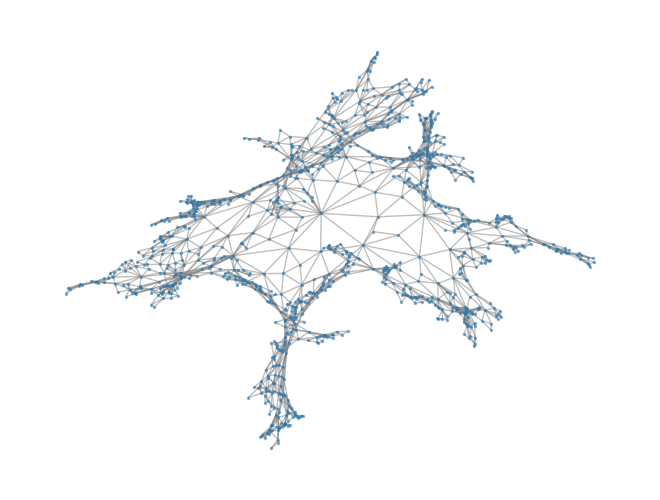

In [9]:
## visualize the graph
nx.draw(G, with_labels=False, node_size=2, edge_color='gray', alpha=0.5)

### 1. Detect all facets <a class="anchor" id="1"></a>

**facets** are the maximal simplices in a simplicial complex. In the context of a graph, facets correspond to the maximal cliques. 


In [36]:
## find the all cliques in G
cliques = list(nx.enumerate_all_cliques(G))
cliques.sort(key=lambda x: len(x), reverse=True)

## remove all the cliques that are subsets of the maximum cliques
## Important they need to be sorted in reverse order before the for loop 
facets = []
for c in cliques:
    if not any(set(c).issubset(set(f)) for f in facets):
        facets.append(c)
facets.sort(key=lambda x: len(x), reverse=False)

print(f"Number of facets: {len(facets)}")
print(f"Facets of size 2: {len([f for f in facets if len(f) == 2])}")
facets

Number of facets: 1310
Facets of size 2: 21


[[3, 1],
 [1, 2],
 [59, 144],
 [59, 671],
 [347, 342],
 [87, 296],
 [78, 51],
 [144, 118],
 [391, 815],
 [93, 496],
 [564, 475],
 [815, 633],
 [496, 622],
 [764, 622],
 [178, 823],
 [295, 823],
 [738, 687],
 [270, 309],
 [397, 568],
 [217, 309],
 [329, 535],
 [0, 3, 4],
 [0, 3, 5],
 [3, 5, 9],
 [3, 6, 7],
 [3, 7, 9],
 [5, 2, 9],
 [2, 6, 7],
 [2, 7, 8],
 [2, 7, 9],
 [2, 7, 15],
 [2, 8, 11],
 [2, 9, 12],
 [2, 11, 15],
 [2, 12, 13],
 [2, 13, 14],
 [2, 14, 15],
 [7, 9, 10],
 [7, 15, 17],
 [7, 10, 16],
 [7, 16, 17],
 [9, 12, 10],
 [12, 13, 25],
 [12, 19, 20],
 [12, 19, 25],
 [12, 20, 24],
 [12, 24, 25],
 [12, 25, 26],
 [13, 14, 18],
 [13, 25, 18],
 [14, 15, 17],
 [14, 17, 18],
 [10, 16, 21],
 [10, 27, 29],
 [10, 29, 32],
 [16, 17, 43],
 [16, 21, 22],
 [16, 22, 43],
 [17, 18, 23],
 [17, 23, 33],
 [17, 33, 39],
 [17, 39, 55],
 [17, 55, 68],
 [17, 68, 101],
 [17, 69, 76],
 [17, 76, 90],
 [17, 90, 105],
 [17, 105, 101],
 [25, 26, 28],
 [25, 18, 46],
 [25, 28, 30],
 [25, 30, 81],
 [25, 46, 72],


#### Is this simplicial complex pure? <a class="anchor" id="pure"></a>

No it is not since it has facets of different dimensions. A pure simplicial complex is one in which all facets have the same dimension.

### 2. Calculate distributions <a class="anchor" id="2"></a>

- edges per node 
- triangles per node 
- triangles per edge

In [97]:
## k_{1,0} distribution would be the distribution of the node degrees in G
# https://networkx.org/documentation/stable/auto_examples/drawing/plot_degree.html

degree_sequence = list(d for n, d in G.degree())

## triangles per node
# https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.cluster.triangles.html

triangle_sequence = [nx.triangles(G, n) for n in G.nodes()]


## this does not work because nx.triangles() takes a node as input, not an edge. We need to find the number of triangles that each edge is part of.
# triangle_per_edge = [nx.triangles(G, e) for e in G.edges()]
# triangle_per_edge

## get triangles per edge
triangles = [c for c in cliques if len(c) == 3]
dict_triangles = {}
degrees_21 = []
for e in G.edges():
    count = 0
    for t in triangles:
        if e[0] in t and e[1] in t:
            count += 1
    dict_triangles[e] = count
    degrees_21.append(count)


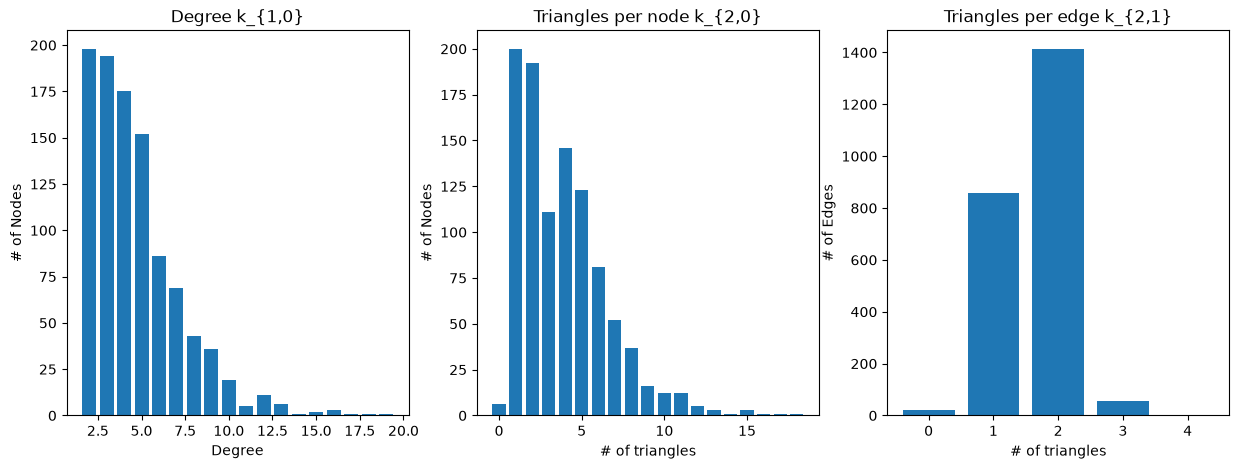

In [96]:
## Subplot with the 3 distributions
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].bar(*np.unique(degree_sequence, return_counts=True))
axs[0].set_title("Degree k_{1,0}")
axs[0].set_xlabel("Degree")
axs[0].set_ylabel("# of Nodes")

axs[1].bar(*np.unique(triangle_sequence, return_counts=True))
axs[1].set_title("Triangles per node k_{2,0}")
axs[1].set_xlabel("# of triangles")
axs[1].set_ylabel("# of Nodes")

axs[2].bar(*np.unique(degrees_21, return_counts=True))
axs[2].set_title("Triangles per edge k_{2,1}")
axs[2].set_xlabel("# of triangles")
axs[2].set_ylabel("# of Edges")

plt.show()

### 3. Classify all edges into 2-saturated and 2-unsaturated. <a class="anchor" id="3"></a>

In [ ]:
print(f"number of edges: {len(dict_triangles)}")

assert len(dict_triangles) == G.number_of_edges()

saturated_2_edges = [e for e in G.edges() if dict_triangles[e] >= 2]
unsaturated_2_edges = [e for e in G.edges() if dict_triangles[e] < 2]

print(f"number of 2-saturated edges: {len(saturated_2_edges)}")
print(f"number of 2-unsaturated edges: {len(unsaturated_2_edges)}")

number of edges: 2353
number of 2-saturated edges: 1473
number of 2-unsaturated edges: 880


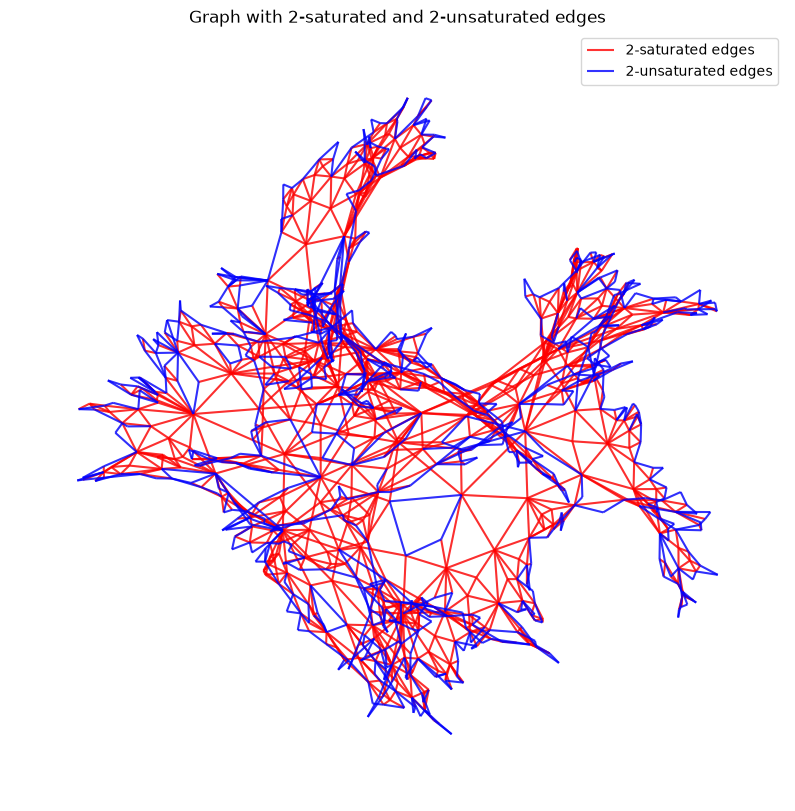

In [126]:
## plot a subset of edges over the original graph
plt.figure(figsize=(10, 10))
pos = nx.spring_layout(G, seed=42)

# Draw the full graph in the background.
nx.draw_networkx_nodes(G, pos, node_size=0)
nx.draw_networkx_edges(G, pos, edge_color="lightgray", alpha=0.4)

# Draw whichever edge subset should be highlighted.
nx.draw_networkx_edges(G,pos,edgelist=saturated_2_edges,edge_color="red",width=1.5,alpha=0.8, label="2-saturated edges")
nx.draw_networkx_edges(G,pos,edgelist=unsaturated_2_edges,edge_color="blue",width=1.5,alpha=0.8, label="2-unsaturated edges")

plt.title("Graph with 2-saturated and 2-unsaturated edges")
plt.axis("off")
plt.legend()
plt.show()

### 4. Detect the 1-connected components <a class="anchor" id="4"></a>


this implies finding the connected components of the graph formed by the 2-saturated edges.  and detecting those edges that belong to only one triangle.

In [132]:
not_triangle_edges = [e for e in G.edges() if dict_triangles[e] == 0]

print(f"number of edges that do not belong to any triangle: {len(not_triangle_edges)}")

number of edges that do not belong to any triangle: 21


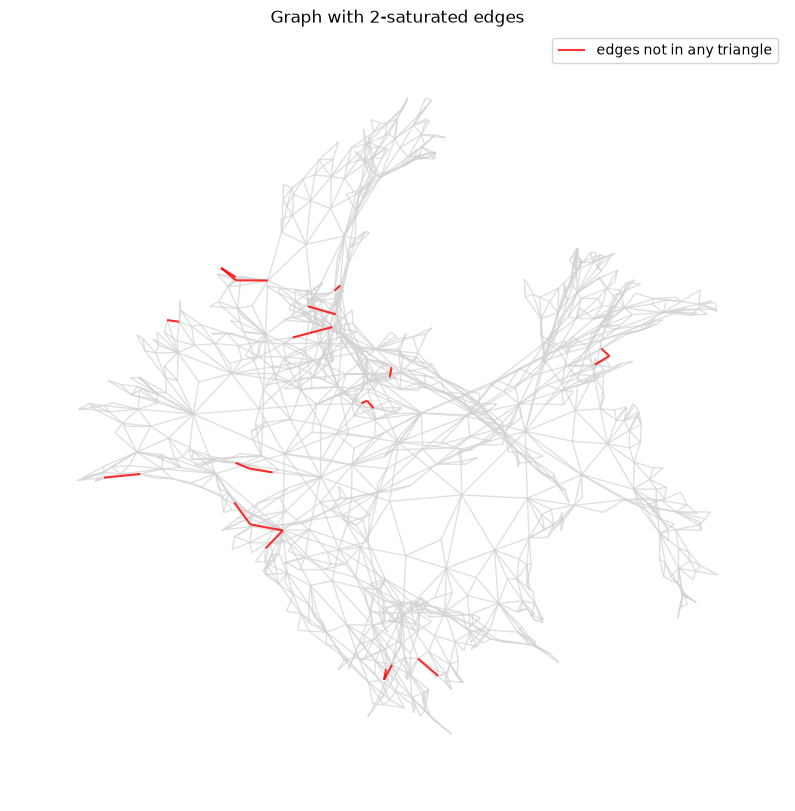

In [133]:
## plot a subset of edges over the original graph
plt.figure(figsize=(10, 10))
pos = nx.spring_layout(G, seed=42)

# Draw the full graph in the background.
nx.draw_networkx_nodes(G, pos, node_size=0)
nx.draw_networkx_edges(G, pos, edge_color="lightgray", alpha=0.7)

# Draw whichever edge subset should be highlighted.
#nx.draw_networkx_edges(G,pos,edgelist=saturated_2_edges,edge_color="blue",width=1.5,alpha=0.6, label="2-saturated edges")
nx.draw_networkx_edges(G,pos,edgelist=not_triangle_edges,edge_color="red",width=1.5,alpha=0.8, label="edges not in any triangle")

plt.title("Graph with 2-saturated edges")
plt.axis("off")
plt.legend()
plt.show()